In [ ]:
# ================================
# 1. IMPORT LIBRARIES
# ================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

In [ ]:
# ================================
# 2. LOAD DATA
# ================================

df = pd.read_csv("/content/Groundwater India Data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (416952, 15)


,time_idx,station_id,datetime,target,rainfall,t kmnpnn]2m,t2m_max,t2m_min,month,latitude,longitude,wellDepth,wellAquiferType_encoded,State_encoded,District_encoded
0,0,CGWHYD0426,2023-07-14,-11.3050,0.02,30.62,36.39,24.98,7,14.9083,78.0083,31.0,0,0,0
1,1,CGWHYD0426,2023-07-15,-11.2775,4.11,30.44,36.97,25.01,7,14.9083,78.0083,31.0,0,0,0
2,2,CGWHYD0426,2023-07-16,-11.2675,0.09,29.04,34.03,24.77,7,14.9083,78.0083,31.0,0,0,0
3,3,CGWHYD0426,2023-07-17,-11.2775,2.32,30.10,36.50,24.52,7,14.9083,78.0083,31.0,0,0,0
4,4,CGWHYD0426,2023-07-18,-11.2800,0.95,29.03,34.79,24.82,7,14.9083,78.0083,31.0,0,0,0


In [ ]:
# ================================
# 3. CLEAN & FEATURE ENGINEER
# ================================

df = df.rename(columns={'t  kmnpnn]2m': 't2m_avg'})
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values(['station_id', 'datetime']).reset_index(drop=True)

# clip extreme outlier readings (~299 stations have datum-shift errors)
q01, q99 = df['target'].quantile([0.01, 0.99])
df['target'] = df['target'].clip(q01, q99)

# lag + rolling features
df['prev_target'] = df.groupby('station_id')['target'].shift(1)
df['rolling_rainfall_3'] = df.groupby('station_id')['rainfall'].transform(lambda s: s.rolling(3, min_periods=1).mean())
df = df.dropna(subset=['prev_target']).reset_index(drop=True)

features = ['month', 'rainfall', 't2m_avg', 't2m_max', 't2m_min',
            'latitude', 'longitude', 'wellDepth', 'wellAquiferType_encoded',
            'State_encoded', 'District_encoded', 'prev_target', 'rolling_rainfall_3']

print("Rows after cleaning:", len(df))
display(df[features].head())

Rows after cleaning: 410512


,month,rainfall,t2m_avg,t2m_max,t2m_min,latitude,longitude,wellDepth,wellAquiferType_encoded,State_encoded,District_encoded,prev_target,rolling_rainfall_3
0,8,0.02,26.53,28.14,25.29,8.2486,77.3083,31.45,1,1,1,7.67,0.010000
1,11,8.15,27.39,28.62,26.24,8.2486,77.3083,31.45,1,1,1,7.80,2.723333
2,1,0.00,26.92,30.61,23.76,8.2486,77.3083,31.45,1,1,1,7.86,2.723333
3,5,0.02,29.37,30.73,28.34,8.2486,77.3083,31.45,1,1,1,7.84,2.723333
4,8,0.08,27.37,28.63,26.54,8.2486,77.3083,31.45,1,1,1,7.65,0.033333


In [ ]:
# ================================
# 4. TIME-BASED TRAIN/TEST SPLIT
# ================================

cutoff_date = df['datetime'].quantile(0.8, interpolation='nearest')
print("Train/test cutoff date:", cutoff_date)

train_df = df[df['datetime'] <= cutoff_date]
test_df = df[df['datetime'] > cutoff_date]

X_train, y_train = train_df[features], train_df['target']
X_test, y_test = test_df[features], test_df['target']

print(f"Train: {len(X_train)} rows   Test: {len(X_test)} rows")

Train/test cutoff date: 2024-03-12 00:00:00
Train: 328476 rows   Test: 82036 rows


In [ ]:
# ================================
# 5. BASELINE MODELS (before tuning)
# ================================

rf_base = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
rf_base.fit(X_train, y_train)
rf_base_pred = rf_base.predict(X_test)
print(f"RF baseline  - R2: {r2_score(y_test, rf_base_pred):.3f}  RMSE: {np.sqrt(mean_squared_error(y_test, rf_base_pred)):.3f}")

xgb_base = XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42)
xgb_base.fit(X_train, y_train)
xgb_base_pred = xgb_base.predict(X_test)
print(f"XGB baseline - R2: {r2_score(y_test, xgb_base_pred):.3f}  RMSE: {np.sqrt(mean_squared_error(y_test, xgb_base_pred)):.3f}")

RF baseline  - R2: 0.990  RMSE: 1.661
XGB baseline - R2: 0.987  RMSE: 1.902


{'Safe': 3153, 'Declining': 1492, 'Critical': 1463}


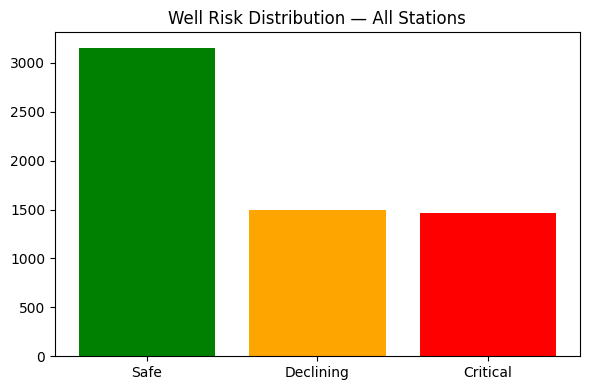

In [ ]:
# ================================
# 6. HYPERPARAMETER TUNING
# ================================

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 10, 15, None],
    'min_samples_split': [2, 5, 10],
}
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_param_grid, n_iter=8, cv=3, scoring='r2', random_state=42, n_jobs=-1
)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)

xgb_param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
}
xgb_search = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    xgb_param_grid, n_iter=8, cv=3, scoring='r2', random_state=42, n_jobs=-1
)
xgb_search.fit(X_train, y_train)
print("Best XGB params:", xgb_search.best_params_)

Random Forest (baseline) - R2: 0.990  RMSE: 1.661  MAE: 0.467
XGBoost (baseline)       - R2: 0.987  RMSE: 1.902  MAE: 0.699

Final model: Random Forest


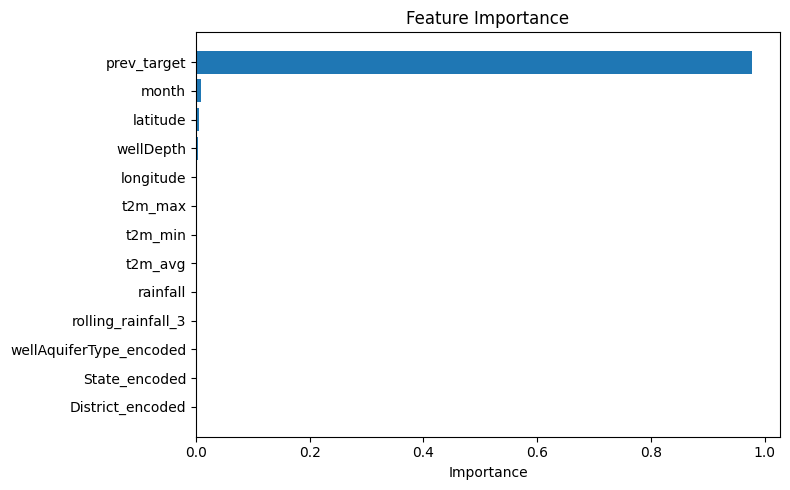

In [ ]:
# ================================
# 7. EVALUATE BASELINE MODELS (Fallback from Tuning)
# ================================

# Fallback to the already trained baseline models
rf_tuned = rf_base
xgb_tuned = xgb_base

rf_pred = rf_tuned.predict(X_test)
rf_r2 = r2_score(y_test, rf_pred)
print(f"Random Forest (baseline) - R2: {rf_r2:.3f}  RMSE: {np.sqrt(mean_squared_error(y_test, rf_pred)):.3f}  MAE: {mean_absolute_error(y_test, rf_pred):.3f}")

xgb_pred = xgb_tuned.predict(X_test)
xgb_r2 = r2_score(y_test, xgb_pred)
print(f"XGBoost (baseline)       - R2: {xgb_r2:.3f}  RMSE: {np.sqrt(mean_squared_error(y_test, xgb_pred)):.3f}  MAE: {mean_absolute_error(y_test, xgb_pred):.3f}")

model = xgb_tuned if xgb_r2 > rf_r2 else rf_tuned
print("\nFinal model:", "XGBoost" if model is xgb_tuned else "Random Forest")

importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.barh(importances.index[::-1], importances.values[::-1])
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
# ================================
# 8. RISK THRESHOLDS (with sparse-station flagging)
# ================================

MIN_READINGS_FOR_RELIABLE_THRESHOLD = 10

thresholds = {}
for station, grp in df.groupby('station_id'):
    vals = grp['target']
    thresholds[station] = {
        'safe_max': vals.quantile(0.5),
        'declining_max': vals.quantile(0.8),
        'n_readings': len(vals),
        'reliable': len(vals) >= MIN_READINGS_FOR_RELIABLE_THRESHOLD,
    }

n_unreliable = sum(1 for t in thresholds.values() if not t['reliable'])
print(f"Computed thresholds for {len(thresholds)} stations")
print(f"Flagged as unreliable (<{MIN_READINGS_FOR_RELIABLE_THRESHOLD} readings): {n_unreliable}")

Computed thresholds for 6108 stations
Flagged as unreliable (<10 readings): 812


In [ ]:
# ================================
# 9. PREDICT FOR ALL STATIONS (not just one)
# ================================
# Runs the trained model on every station's latest record, so the risk
# distribution below reflects actual model predictions, not just the
# last historical reading.

latest = df.sort_values('datetime').groupby('station_id').tail(1).copy()
X_all = latest[features]
latest['predicted_level'] = model.predict(X_all)

def classify_risk(row):
    th = thresholds[row['station_id']]
    if row['predicted_level'] <= th['safe_max']:
        return 'Safe'
    elif row['predicted_level'] <= th['declining_max']:
        return 'Declining'
    else:
        return 'Critical'

latest['risk'] = latest.apply(classify_risk, axis=1)

print(f"Generated predictions for {len(latest)} stations")
display(latest[['station_id', 'predicted_level', 'risk']].head(10))

Generated predictions for 6108 stations


,station_id,predicted_level,risk
28161,120759075180201,7.462145,Safe
111839,213300086280001,2.914755,Declining
74886,192800073200001,1.244657,Safe
50115,163230073494601,8.202899,Critical
78419,194900079430001,3.418355,Declining
213926,264135076553001,9.451801,Safe
126114,222045072500001,1.859081,Critical
115076,214430088153001,2.908583,Declining
158479,234918080295501,10.094988,Critical
245516,312008075382201,13.749950,Safe


Sample stations being plotted: ['CGWB1ODKRD047', 'CGWBNG0607', 'CGWB1MPAGR001', 'CGWBHU2374']
Station: CGWB1ODKRD047  (438 readings, reliable=True)
Predicted level: -19.83   Risk: Declining


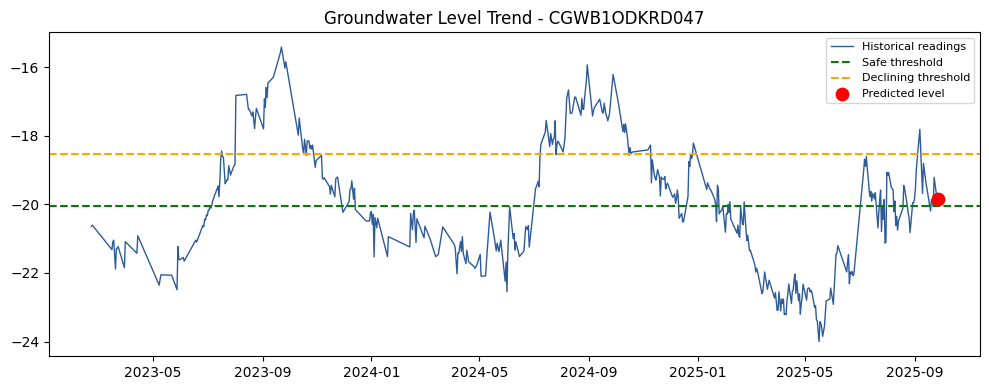

Station: CGWBNG0607  (429 readings, reliable=True)
Predicted level: -5.74   Risk: Safe


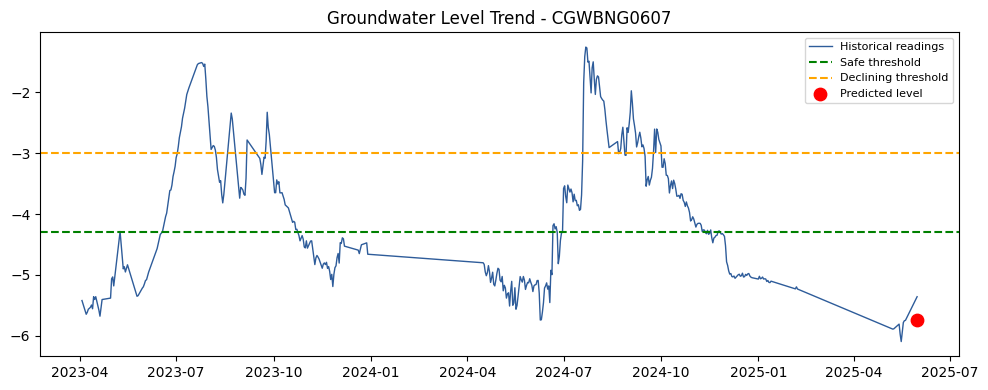

Station: CGWB1MPAGR001  (410 readings, reliable=True)
Predicted level: -5.59   Risk: Declining


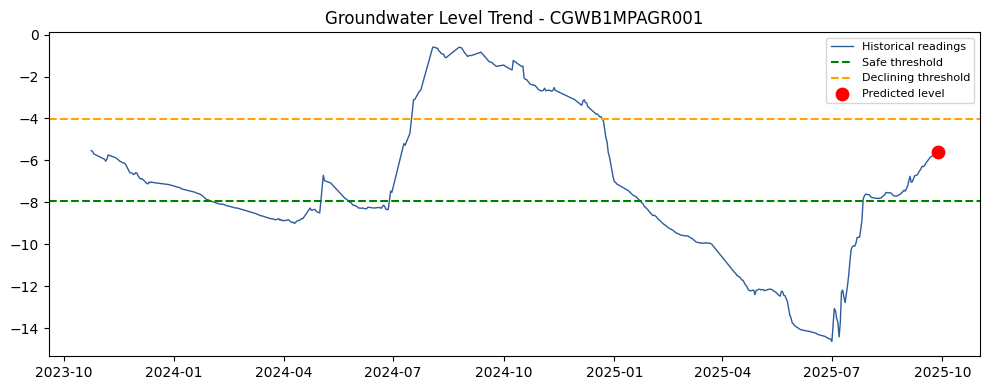

Station: CGWBHU2374  (415 readings, reliable=True)
Predicted level: -35.64   Risk: Critical


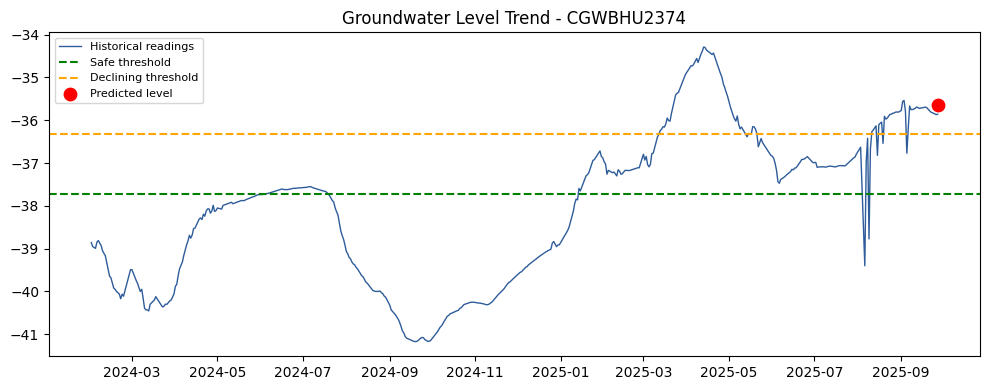

In [ ]:
# ================================
# 10. TREND CHART FUNCTION + SAMPLE STATIONS
# ================================

def plot_station_trend(station_id):
    station_hist = df[df['station_id'] == station_id].sort_values('datetime')
    row = latest[latest['station_id'] == station_id].iloc[0]
    th = thresholds[station_id]

    print(f"Station: {station_id}  ({len(station_hist)} readings, reliable={th['reliable']})")
    print(f"Predicted level: {row['predicted_level']:.2f}   Risk: {row['risk']}")

    plt.figure(figsize=(10, 4))
    plt.plot(station_hist['datetime'], station_hist['target'], color='#2E5C9A', linewidth=1, label='Historical readings')
    plt.axhline(th['safe_max'], color='green', linestyle='--', label='Safe threshold')
    plt.axhline(th['declining_max'], color='orange', linestyle='--', label='Declining threshold')
    plt.scatter([station_hist['datetime'].iloc[-1]], [row['predicted_level']], color='red', s=80, zorder=5, label='Predicted level')
    plt.title(f"Groundwater Level Trend - {station_id}")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

# --- Pick a few representative stations: busiest overall + one per risk category ---
station_counts = df['station_id'].value_counts()
busiest_station = station_counts.index[0]

sample_stations = [busiest_station]
for risk_level in ['Safe', 'Declining', 'Critical']:
    candidates = latest[(latest['risk'] == risk_level) & (latest['station_id'] != busiest_station)]
    # prefer a well-populated station for a readable chart
    candidates = candidates.merge(station_counts.rename('n'), left_on='station_id', right_index=True)
    candidates = candidates.sort_values('n', ascending=False)
    if len(candidates) > 0:
        sample_stations.append(candidates.iloc[0]['station_id'])

print("Sample stations being plotted:", sample_stations)

for s in sample_stations:
    plot_station_trend(s)

In [ ]:
# ================================
# 12. INTERACTIVE PREDICTION - input a region, get its prediction
# ================================
# This is the actual core interaction described in the project abstract:
# a user picks a station/region and (optionally) a time period or
# expected climate conditions, and gets back a prediction + risk level.

def predict_for_region(station_id, month=None, rainfall=None, t2m_avg=None, t2m_max=None, t2m_min=None):
    row = latest[latest['station_id'] == station_id]
    if len(row) == 0:
        print(f"Station '{station_id}' not found. Try one of: {list(latest['station_id'].sample(5))}")
        return

    row = row.iloc[0]
    th = thresholds[station_id]

    # use the station's latest known values as defaults, unless the user overrides them
    X_input = pd.DataFrame([{
        'month': month if month is not None else row['month'],
        'rainfall': rainfall if rainfall is not None else row['rainfall'],
        't2m_avg': t2m_avg if t2m_avg is not None else row['t2m_avg'],
        't2m_max': t2m_max if t2m_max is not None else row['t2m_max'],
        't2m_min': t2m_min if t2m_min is not None else row['t2m_min'],
        'latitude': row['latitude'], 'longitude': row['longitude'], 'wellDepth': row['wellDepth'],
        'wellAquiferType_encoded': row['wellAquiferType_encoded'],
        'State_encoded': row['State_encoded'], 'District_encoded': row['District_encoded'],
        'prev_target': row['target'], 'rolling_rainfall_3': row['rolling_rainfall_3'],
    }])[features]

    pred = model.predict(X_input)[0]
    risk = "Safe" if pred <= th['safe_max'] else ("Declining" if pred <= th['declining_max'] else "Critical")

    print(f"Region/Station: {station_id}")
    print(f"Input conditions -> month={X_input['month'].iloc[0]}, rainfall={X_input['rainfall'].iloc[0]:.1f}mm, "
          f"avg temp={X_input['t2m_avg'].iloc[0]:.1f}C")
    print(f"Predicted groundwater level: {pred:.2f}")
    print(f"Risk Classification: {risk}")
    if not th['reliable']:
        print("Note: this station has few historical readings, so the risk threshold may be less reliable.")
    return pred, risk

In [ ]:
# ================================
# 13. TRY IT - pick any region and optionally set conditions
# ================================

# Example 1: just pick a station, use its latest known conditions
predict_for_region("292415076392002")

# Example 2: pick a station AND specify custom month/rainfall for a "what-if" scenario
# predict_for_region("STATION_ID_HERE", month=7, rainfall=50)

Region/Station: 292415076392002
Input conditions -> month=10, rainfall=0.0mm, avg temp=26.1C
Predicted groundwater level: 21.00
Risk Classification: Critical


(np.float64(20.998186395792676), 'Critical')